# Sabotage Connectome

When doing simulations, you generate the activity from an initial connectome. If you reconstruct using that same connectome, you are in an ideal case, most likely never happening in reality. To induce incertitudes in your reconstruction, you can sabotage your connectome to see how your method would perform in case your connectome is different. <br>
There are multiple ways of sabotaging a graph. You can:
- Permutate some connections
- Add new connections
- Delete existing connections

In this notebook you can experiment with the `sabotage_connectome()` function to see the differences.

## 📦 Imports

In [1]:
import mindmap as mm
import pygsp as pg
import matplotlib.pyplot as plt

## 🧠 Data


📥 **<font color=pink>Inputs</font>**
- `sc`: Structural connectome
- `src`: Source space

🎚️ **<font color=pink>Configuration</font>**:
- `fconfig`: Configuration file.
- `sub`: Subject id (position in list SUBS)

In [2]:
############# Parameters ################
# configuration
fconfig = "../../papers/simf/configuration.yml"
subject = 1
#########################################

reader = mm.io.dataset_reader(fconfig)
data   = reader(subject, "sc", "eeg", "fwd", "cst", "sc_tmp", "parc", "cras")

Coregistered EEG found
DATA SUMMARY
Dataset: simf
Subject: vepcon_sub-10
Retrieved objects:
- parc
- sc_tmp
- cras
- cst
- fwd
- sc
- eeg
Missing objects:


## Run simulation with True connectome

In [3]:
sim = mm.utils.Simulation(data["fwd"], data["sc"], data["eeg"].info, data["parc"], data["cras"])
sim.set_prop_attr(conduction=0)
sim.run()

AttributeError: 'NoneType' object has no attribute 'copy'

## Run source reconstruction with sabotaged connectome

#### ⚙️ <font color=green>**Sabotage**</font>

🎚️ **<font color=pink>Options</font>**:
- `deletions`: Number of random connections to delete.
- `additions`: Number of random connections to add

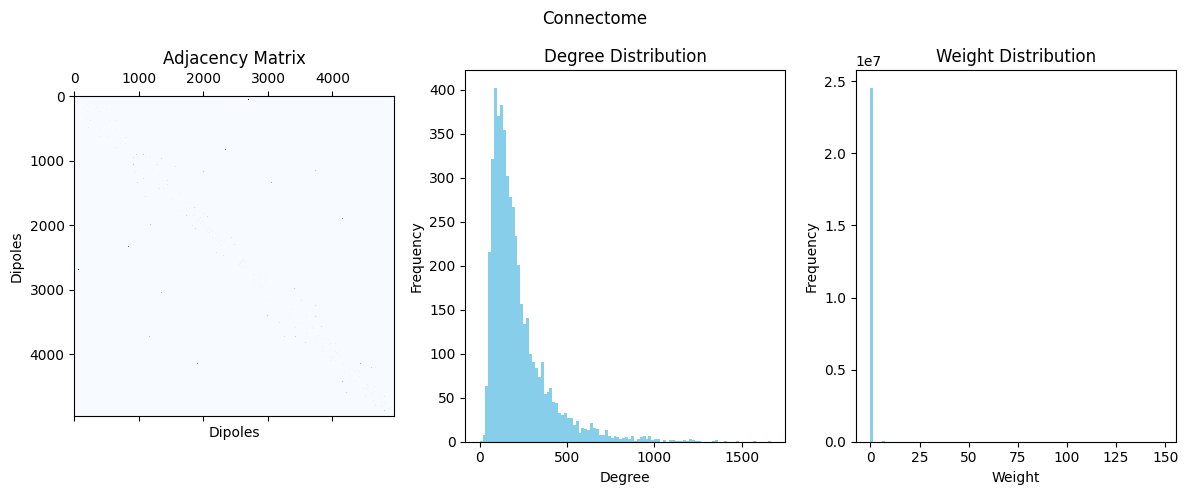

In [5]:
mm.viz.plot_connectome(data["sc"])

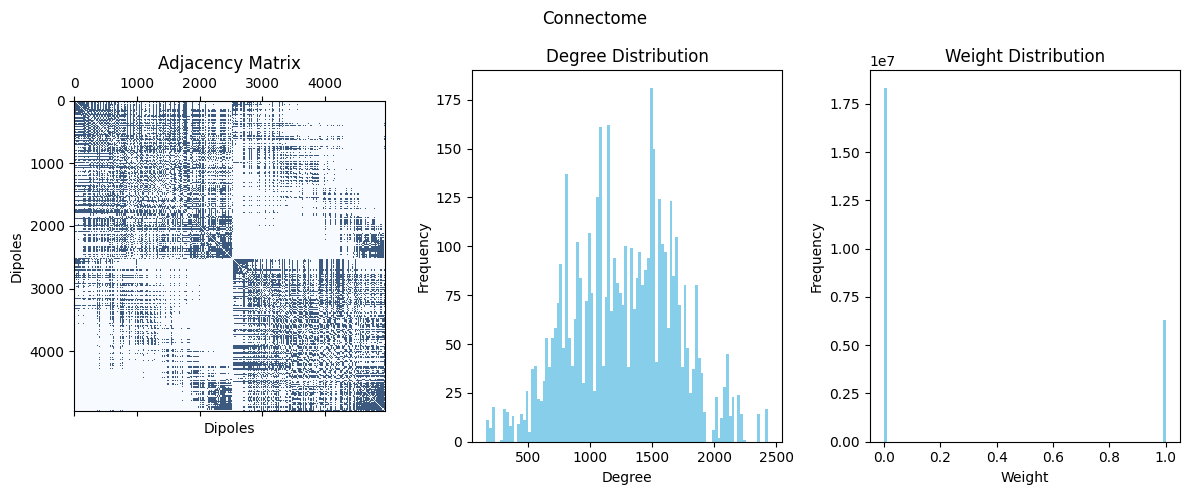

In [6]:
mm.viz.plot_connectome(data["sc_tmp"])

In [7]:
################### Parameters ###################
# sabotage
deletions = 0.6 * data["sc"].sum() / 2
additions = 0.6 * data["sc"].sum() / 2
##################################################

mask = mm.utils.build_geometry(data["fwd"]["src"], dmax=10, conn_hemis=True).astype(bool)
sc   = mm.utils.sabotage_connectome(data["sc"], deletions=int(deletions), additions=int(additions))

mm.viz.plot_connectome(sc, name=f"{int(deletions)} deletions and {int(additions)} additions")

TypeError: build_geometry() got an unexpected keyword argument 'conn_hemis'

In [6]:
import numpy as np
print(np.sum(mask*sc)/np.sum(mask))

0.4010023951033443


In [7]:
graph = pg.graphs.Graph(mask, lap_type="normalized")
graph.compute_fourier_basis()

eigvals = graph.e
cst     = graph.U.T


mm.viz.plot_harmonics(data["fwd"]["src"], cst, frequencies=[6,7,8,9,10,11]).show()

/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/pygsp/graphs/graph.py:496: RuntimeWarning: divide by zero encountered in power
  d = np.power(self.dw, -0.5)
2025-07-17 09:53:54,203:[WARNING](pygsp.graphs.graph.compute_fourier_basis): Computing the full eigendecomposition of a large matrix (4961 x 4961) may take some time.
ERROR:root:Could not find a decent config
2025-07-17 09:54:00.084 (  20.527s) [    78CFC573B600]vtkXOpenGLRenderWindow.:256    ERR| vtkXOpenGLRenderWindow (0x85d7470): Could not find a decent config



: 

In [ ]:
mm.viz.plot_harmonics(data["fwd"])


#### ⚙️ <font color=green>**Source reconstruction**</font>

In [11]:
# connectomics
graph = pg.graphs.Graph(sc, lap_type="normalized")
graph.compute_fourier_basis()

eigvals = graph.e
cst     = graph.U.T

geom = mm.utils.build_geometry(data["fwd"]["src"], dmax=10, conn_hemis=True)
geom = pg.graphs.Graph(geom, lap_type="normalized")
geom.compute_fourier_basis()

geom_eigvals = geom.e
geom_cst     = geom.U.T

weights = mm.utils.harmonic_weights(eigvals, relaxation = 0.2)
geom_weights = mm.utils.harmonic_weights(geom_eigvals, relaxation = 0.2)

# source reconstruction
stc_cset       = mm.cset(sim.eeg, fwd=data["fwd"], cst=cst, lam=0.1)
stc_geo_cset   = mm.cset(sim.eeg, fwd=data["fwd"], cst=geom_cst, lam=0.1)
stc_cset_true  = mm.cset(sim.eeg, fwd=data["fwd"], cst=data["cst"], lam=0.1)
stc_wcset      = mm.wcset(sim.eeg, data["fwd"], cst, weights, lam=0.1)
stc_geo_wcset  = mm.wcset(sim.eeg, data["fwd"], geom_cst, geom_weights, lam=0.1)
stc_wcset_true = mm.wcset(sim.eeg, data["fwd"], data["cst"], weights, lam=0.1)
stc_sloreta    = mm.sloreta(sim.eeg, data["fwd"], lam=0.001)

2025-07-17 10:50:05,308:[WARNING](pygsp.graphs.graph.compute_fourier_basis): Computing the full eigendecomposition of a large matrix (4961 x 4961) may take some time.
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/pygsp/graphs/graph.py:496: RuntimeWarning: divide by zero encountered in power
  d = np.power(self.dw, -0.5)
2025-07-17 10:50:10,536:[WARNING](pygsp.graphs.graph.compute_fourier_basis): Computing the full eigendecomposition of a large matrix (4961 x 4961) may take some time.


EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.


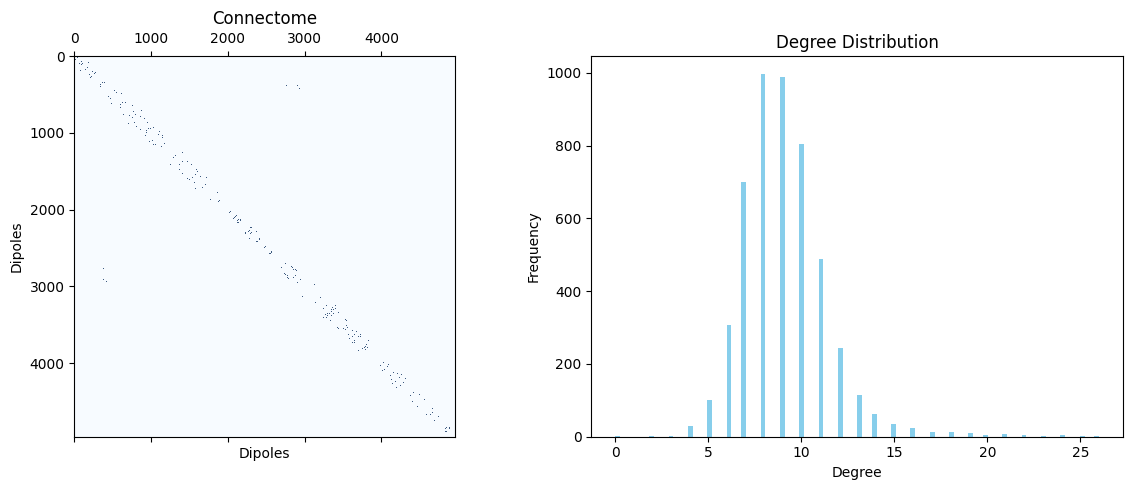

In [12]:
geom = mm.utils.build_geometry(data["fwd"]["src"], dmax=10, conn_hemis=True)
mm.viz.plot_connectome(geom)


#### ⚙️ <font color=green>**Compute correlations and plot**</font>

/home/nino/Code/mindmap/mindmap/utils/misc.py:580: RuntimeWarning: invalid value encountered in divide
  data = data / np.max(np.abs(data), axis=1)[:,None]


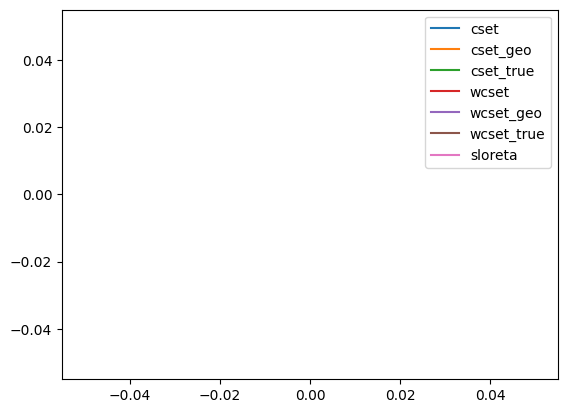

In [18]:
# standardize
gt = mm.utils.standardize_stc(sim.get_activity(noise=False), timepoint_wise=True)

# correlations
correlations = []
for stc in [stc_cset, stc_geo_cset, stc_cset_true, stc_wcset, stc_geo_wcset, stc_wcset_true, stc_sloreta]:
    stc_std = mm.utils.standardize_stc(stc, timepoint_wise=True)
    corr    = mm.utils.compute_stc_correlation(stc_std, gt)
    correlations.append(corr)

times = gt.times

plt.Figure()
for corr in correlations:
    plt.plot(times, corr)
plt.legend(["cset", "cset_geo", "cset_true", "wcset", "wcset_geo", "wcset_true", "sloreta"])
plt.show()